<a href="https://colab.research.google.com/github/bimaadiwijaya8/-ML_05_Bima-Adiwijaya/blob/main/JS07/JS07_Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Memuat dataset
df = pd.read_csv('CC_Customer_Dataset.csv')

# Menampilkan 5 baris pertama dataset
display(df.head())
print(df.info())

,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 660 entries, 0 to 659
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   Sl_No                660 non-null    int64
 1   Customer Key         660 non-null    int64
 2   Avg_Credit_Limit     660 non-null    int64
 3   Total_Credit_Cards   660 non-null    int64
 4   Total_visits_bank    660 non-null    int64
 5   Total_visits_online  660 non-null    int64
 6   Total_calls_made     660 non-null    int64
dtypes: int64(7)
memory usage: 36.2 KB
None


### Soal 1: Membuat Scatterplot dan Analisis Linieritas
Membuat *scatterplot* menggunakan variabel `Avg_Credit_Limit` dan `Total_Credit_Cards` untuk melihat apakah sebaran data memiliki pola linier[cite: 1].

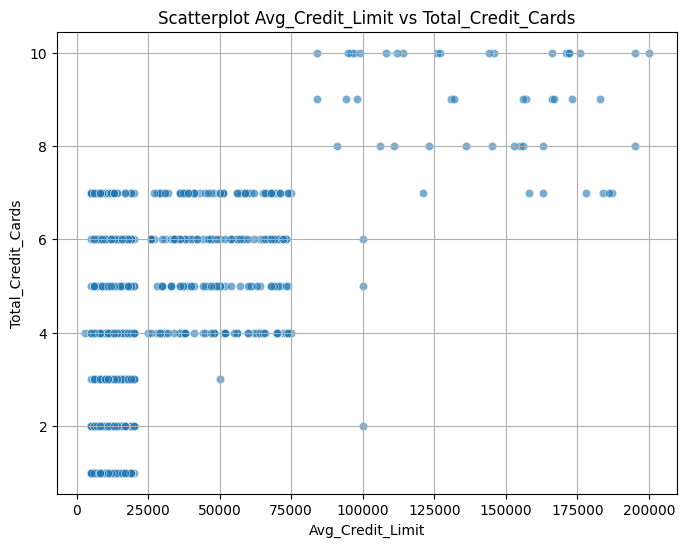

In [5]:
plt.figure(figsize=(8, 6))
# Mengubah 'Total_credit_card' menjadi 'Total_Credit_Cards'
sns.scatterplot(data=df, x='Avg_Credit_Limit', y='Total_Credit_Cards', alpha=0.6)
plt.title('Scatterplot Avg_Credit_Limit vs Total_Credit_Cards')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.grid(True)
plt.show()

**Analisis Sebaran Data:**
Berdasarkan *scatterplot* di atas, sebaran data antara `Avg_Credit_Limit` dan `Total_Credit_Cards` **tidak dapat dikatakan linier**[cite: 1]. Titik-titik data terdistribusi dalam kelompok-kelompok terpisah secara vertikal untuk setiap jumlah kartu kredit, alih-alih membentuk garis lurus diagonal yang konsisten.

### Soal 2: Model Klasterisasi K-Means & Elbow Method
Menentukan jumlah klaster ($k$) terbaik menggunakan *Elbow Method* dengan memplot nilai *Inertia* dari fitur-fitur numerik (kolom ID seperti `Sl_No` dan `Customer Key` di-*drop* karena bukan variabel analisis)[cite: 1].

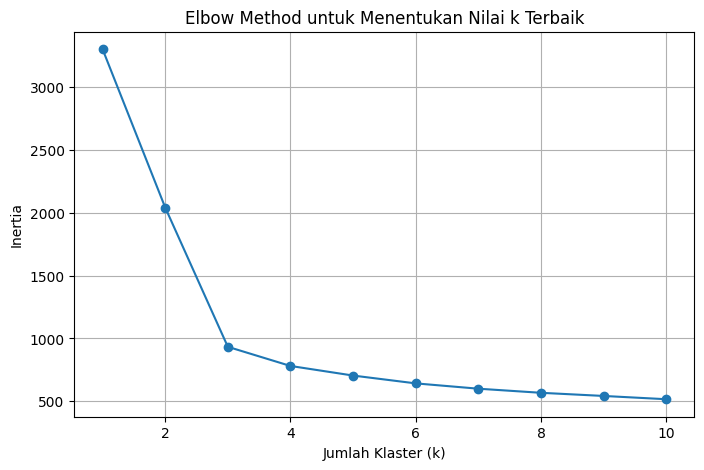

In [6]:
# Membuang kolom ID/non-analisis, lalu ambil fitur numerik
X_kmeans = df.drop(columns=['Sl_No', 'Customer Key'])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_kmeans)

inertias = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

# Plot Elbow Method (Linechart)
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertias, marker='o', linestyle='-')
plt.title('Elbow Method untuk Menentukan Nilai k Terbaik')
plt.xlabel('Jumlah Klaster (k)')
plt.ylabel('Inertia')
plt.grid(True)
plt.show()

**Analisis Pemilihan Nilai $k$ (*Elbow Method*):**
Berdasarkan *linechart* di atas, kurva mengalami pelandaian yang signifikan (membentuk siku atau *elbow*) pada nilai **$k = 3$**. Oleh karena itu, nilai $k = 3$ dipilih sebagai jumlah klaster optimal karena penambahan klaster setelah titik tersebut tidak memberikan penurunan *inertia* yang drastis[cite: 1].

### Soal 3: Visualisasi Hasil Klasterisasi K-Means dengan Scatterplot
Menerapkan model K-Means dengan jumlah klaster terpilih ($k = 3$) dan memvisualisasikannya ke dalam bentuk *scatterplot*[cite: 1].

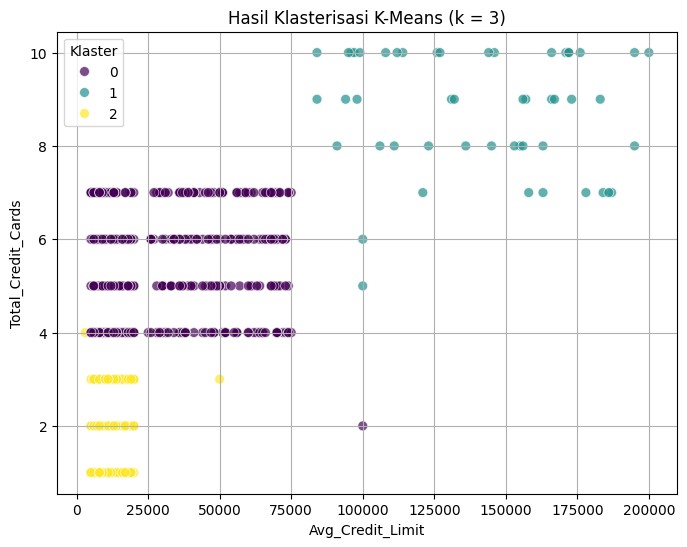

In [7]:
# Menjalankan K-Means dengan k = 3
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

# Visualisasi hasil klasterisasi K-Means
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df,
    x='Avg_Credit_Limit',
    y='Total_Credit_Cards',
    hue='KMeans_Cluster',
    palette='viridis',
    alpha=0.7,
    s=50
)
plt.title(f'Hasil Klasterisasi K-Means (k = {optimal_k})')
plt.xlabel('Avg_Credit_Limit')
plt.ylabel('Total_Credit_Cards')
plt.legend(title='Klaster')
plt.grid(True)
plt.show()

### Soal 4: Model Klasterisasi DBSCAN dengan Seluruh Variabel
Membuat model klasterisasi menggunakan algoritma **DBSCAN** dengan memanfaatkan seluruh variabel numerik yang dapat digunakan (setelah membuang kolom ID)[cite: 1].

In [8]:
# Mempersiapkan fitur untuk DBSCAN (menghapus kolom ID dan label klaster sebelumnya)
X_dbscan = df.drop(columns=['Sl_No', 'Customer Key'])
if 'KMeans_Cluster' in X_dbscan.columns:
    X_dbscan = X_dbscan.drop(columns=['KMeans_Cluster'])

scaler_db = StandardScaler()
X_dbscan_scaled = scaler_db.fit_transform(X_dbscan)

# Menjalankan DBSCAN dengan parameter eps dan min_samples
dbscan = DBSCAN(eps=1.5, min_samples=5)
df['DBSCAN_Cluster'] = dbscan.fit_predict(X_dbscan_scaled)

# Menampilkan distribusi klaster (-1 merepresentasikan noise)
print(df['DBSCAN_Cluster'].value_counts())

DBSCAN_Cluster
 0    609
 1     50
-1      1
Name: count, dtype: int64


### Soal 5: Analisis Parameter DBSCAN
*Catatan: DBSCAN tidak menggunakan parameter jumlah klaster $k$ atau *elbow method* konvensional, melainkan berbasis kerapatan (*density-based*).*

**Analisis Parameter:**
Algoritma DBSCAN dikontrol oleh parameter **`eps` ($\epsilon$)** untuk menentukan radius jarak maksimum antar tetangga dan **`min_samples`** untuk menentukan jumlah minimum titik dalam radius tersebut[cite: 1]. Jumlah klaster terbentuk secara otomatis oleh sistem, di mana titik data yang terisolasi dan tidak memenuhi syarat kerapatan akan dilabeli sebagai *noise* (`-1`).

### Soal 6: Menghitung Silhouette Score dan Davies-Bouldin Index (DBI) dari Model DBSCAN
Menghitung metrik evaluasi kualitas klaster (*Silhouette Score* dan *DBI*) khusus untuk titik data yang tergabung dalam klaster valid (mengabaikan titik *noise* bernilai `-1`)[cite: 1].

In [9]:
labels = df['DBSCAN_Cluster']
valid_mask = labels != -1

if len(set(labels[valid_mask])) > 1:
    sil_score = silhouette_score(X_dbscan_scaled[valid_mask], labels[valid_mask])
    dbi_score = davies_bouldin_score(X_dbscan_scaled[valid_mask], labels[valid_mask])
    print(f"Silhouette Score (tanpa noise): {sil_score:.4f}")
    print(f"Davies-Bouldin Index (DBI) (tanpa noise): {dbi_score:.4f}")
else:
    print("Klaster valid yang terbentuk kurang dari 2, metrik evaluasi tidak dapat dihitung.")

Silhouette Score (tanpa noise): 0.5715
Davies-Bouldin Index (DBI) (tanpa noise): 0.6354
